# Task 1: Time-series preprocessing, analysis and modelling
Dataset: Individual Household Electric Power Consumption (Kaggle version of the UCI dataset)
**Target:** `Global_active_power` (kW), forecast for the **next hour**

## Setup and problem definition
This notebook explores househould electricity usage, prepares hourly features, and evaluates models.

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os, sys, warnings


warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

SEED = 42
DATA_PATH = "household_power_consumption.txt"

for folder in ["src", "models", "outputs", "data/processed"]:
    os.makedirs(folder, exist_ok=True)

## Problem definition and dataset justification
- Problem: Forecasting a household's active power use for the next hour from its recent history.
- Why this matters: Demand planning, spotting waste, supporting tariff decisions
- Why this dataset: One household, minute-level readings over about 4 years (Dec 2006 to Nov 2010), a clear timestamp, and several measured variables.
- Source: Kaggle link:https://www.kaggle.com/datasets/alexandertanev/individual-household-electric-power-consumption
- Differences from the UCI original: The Kaggle copy has 2,075,259 rows covering 16 Dec 2006 to 26 Nov 2010, the same size as the UCI original. Source: https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption

## Shared preprocessing module
The shared module converts minute-level data to hourly observations, fills only short internal gaps, and creates lag, moving-average, and calendar features. Keeping this logic in one module helps Task 1 and Task 4 use consistent preprocessing.
  


In [35]:
%%writefile src/features.py

import pandas as pd

TARGET = "Global_active_power"
MEAN_COLS = ["Global_active_power", "Global_reactive_power", "Voltage", "Global_intensity"]
SUM_COLS = ["Sub_metering_1", "Sub_metering_2", "Sub_metering_3"]
MAX_GAP_HOURS = 6


def to_hourly(minute_df):

    means = minute_df[MEAN_COLS].resample("h").mean()
    sums = minute_df[SUM_COLS].resample("h").sum(min_count=1)
    return pd.concat([means, sums], axis=1)


def fill_short_gaps(hourly, max_gap=MAX_GAP_HOURS):
    """Linearly interpolate gaps of at most max_gap hours; longer gaps stay NaN."""
    out = hourly.copy()
    interpolated = out.interpolate(method="time", limit_area="inside")
    for col in out.columns:
        is_na = out[col].isna()
        run_id = (is_na != is_na.shift()).cumsum()
        gap_len = is_na.groupby(run_id).transform("sum")
        short = is_na & (gap_len <= max_gap)
        out.loc[short, col] = interpolated.loc[short, col]
    return out


def build_features(hourly):

    out = hourly.copy()
    for lag in (1, 24, 168):
        out[f"lag_{lag}"] = out[TARGET].shift(lag)
    out["ma_24"] = out[TARGET].rolling(24).mean()
    out["ma_168"] = out[TARGET].rolling(168).mean()
    out["hour"] = out.index.hour
    out["dayofweek"] = out.index.dayofweek
    out["month"] = out.index.month
    return out


CALENDAR = ["hour", "dayofweek", "month"]
LAGS = [TARGET, "lag_1", "lag_24", "lag_168"]          # TARGET = the current hour's value
MOVING_AVG = ["ma_24", "ma_168"]
ELECTRICAL = ["Global_reactive_power", "Voltage", "Global_intensity",
              "Sub_metering_1", "Sub_metering_2", "Sub_metering_3"]

FEATURE_SETS = {
    "A: current + lags + calendar": LAGS + CALENDAR,
    "B: A + moving averages": LAGS + CALENDAR + MOVING_AVG,
    "C: B + electrical measurements": LAGS + CALENDAR + MOVING_AVG + ELECTRICAL,
}

Overwriting src/features.py


In [36]:
sys.path.insert(0, ".")
from src.features import (TARGET, to_hourly, fill_short_gaps, build_features,
                          FEATURE_SETS, MAX_GAP_HOURS)

## Understanding the dataset
The dataset contains timestamped electricity measurements from one household. The target, Global_active_power, is measured in kilowatts; the other columns describe reactive power, voltage, current intensity, and three sub-metering readings.

In [37]:
# Load
df = pd.read_csv(DATA_PATH,
                 sep=";",
                 na_values="?",
                 low_memory=False)

df["datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    dayfirst=True)
df = df.drop(columns=["Date", "Time"]).set_index("datetime").sort_index()
df = df.apply(pd.to_numeric, errors="coerce")

print("Shape:", df.shape)
df.head()

Shape: (2075259, 7)


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
datetime,,,,,,,
2006-12-16 17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
2006-12-16 17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2006-12-16 17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
2006-12-16 17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
2006-12-16 17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


## Time range and frequency
The data spans 16 December 2006 to 26 November 2010, approximately 3 years and 11 months. Consecutive records are one minute apart, with no duplicate timestamps or missing minutes in the timestamp index. Missing measurement values still occur even though the timeline itself is continuous.

In [38]:
print("Start:", df.index.min())
print("End:  ", df.index.max())
print("Span: ", df.index.max() - df.index.min())

# Frequency: how far apart are consecutive timestamps?
step = df.index.to_series().diff().value_counts().head(5)
print("\nMost common gaps between rows:\n", step)

# Duplicates and missing timestamps
full_index = pd.date_range(df.index.min(), df.index.max(), freq="min")
print("\nDuplicate timestamps:", df.index.duplicated().sum())
print("Minutes missing from the timeline:", len(full_index) - df.index.nunique())

Start: 2006-12-16 17:24:00
End:   2010-11-26 21:02:00
Span:  1441 days 03:38:00

Most common gaps between rows:
 datetime
0 days 00:01:00    2075258
Name: count, dtype: int64

Duplicate timestamps: 0
Minutes missing from the timeline: 0


The timeline is regular at one-minute intervals. This makes resampling to hourly observations appropriate and allows lag features such as 24 hours to represent a consistent time period.

## Missing values
All seven measurement columns have 25,979 missing values, approximately 1.25% of rows. The missing values occur in the same records, and the longest consecutive missing stretch in the target is 7,226 minutes (about five days).

In [39]:
missing = pd.DataFrame({"missing": df.isna().sum(),
                        "percent": (df.isna().mean() * 100).round(2)})
print(missing)

# How long are the gaps? (runs of consecutive missing minutes)
na = df[TARGET].isna()
run_id = (na != na.shift()).cumsum()
minute_gaps = na.groupby(run_id).sum()
minute_gaps = minute_gaps[minute_gaps > 0]

print("\nNumber of gaps:", len(minute_gaps))
print(minute_gaps.describe().round(1))
print("\nLongest gaps (minutes):")
print(minute_gaps.sort_values(ascending=False).head(10).to_string())

                       missing  percent
Global_active_power      25979     1.25
Global_reactive_power    25979     1.25
Voltage                  25979     1.25
Global_intensity         25979     1.25
Sub_metering_1           25979     1.25
Sub_metering_2           25979     1.25
Sub_metering_3           25979     1.25

Number of gaps: 71
count      71.0
mean      365.9
std      1251.5
min         1.0
25%         1.0
50%         1.0
75%         3.0
max      7226.0
Name: Global_active_power, dtype: float64

Longest gaps (minutes):
Global_active_power
138    7226
140    5237
14     3723
100    3305
118    3129
126    2027
104     891
32       83
78       70
34       47


Most missing stretches are short, but a few are long outages. This supports treating short gaps differently from extended gaps instead of replacing all missing values with zero.

## Distribution and outliers
Summary statistics and histograms describe each variable's scale and distribution. Global_active_power is right-skewed (skewness 1.79); about 4.6% of its observed values exceed the IQR upper threshold of 3.36 kW. These high values may reflect genuine periods of heavy usage, so they should not be removed automatically.

                           count     mean    std      min      25%      50%  \
Global_active_power    2049280.0    1.092  1.057    0.076    0.308    0.602   
Global_reactive_power  2049280.0    0.124  0.113    0.000    0.048    0.100   
Voltage                2049280.0  240.840  3.240  223.200  238.990  241.010   
Global_intensity       2049280.0    4.628  4.444    0.200    1.400    2.600   
Sub_metering_1         2049280.0    1.122  6.153    0.000    0.000    0.000   
Sub_metering_2         2049280.0    1.299  5.822    0.000    0.000    0.000   
Sub_metering_3         2049280.0    6.458  8.437    0.000    0.000    1.000   

                           75%      max  
Global_active_power      1.528   11.122  
Global_reactive_power    0.194    1.390  
Voltage                242.890  254.150  
Global_intensity         6.400   48.400  
Sub_metering_1           0.000   88.000  
Sub_metering_2           1.000   80.000  
Sub_metering_3          17.000   31.000  


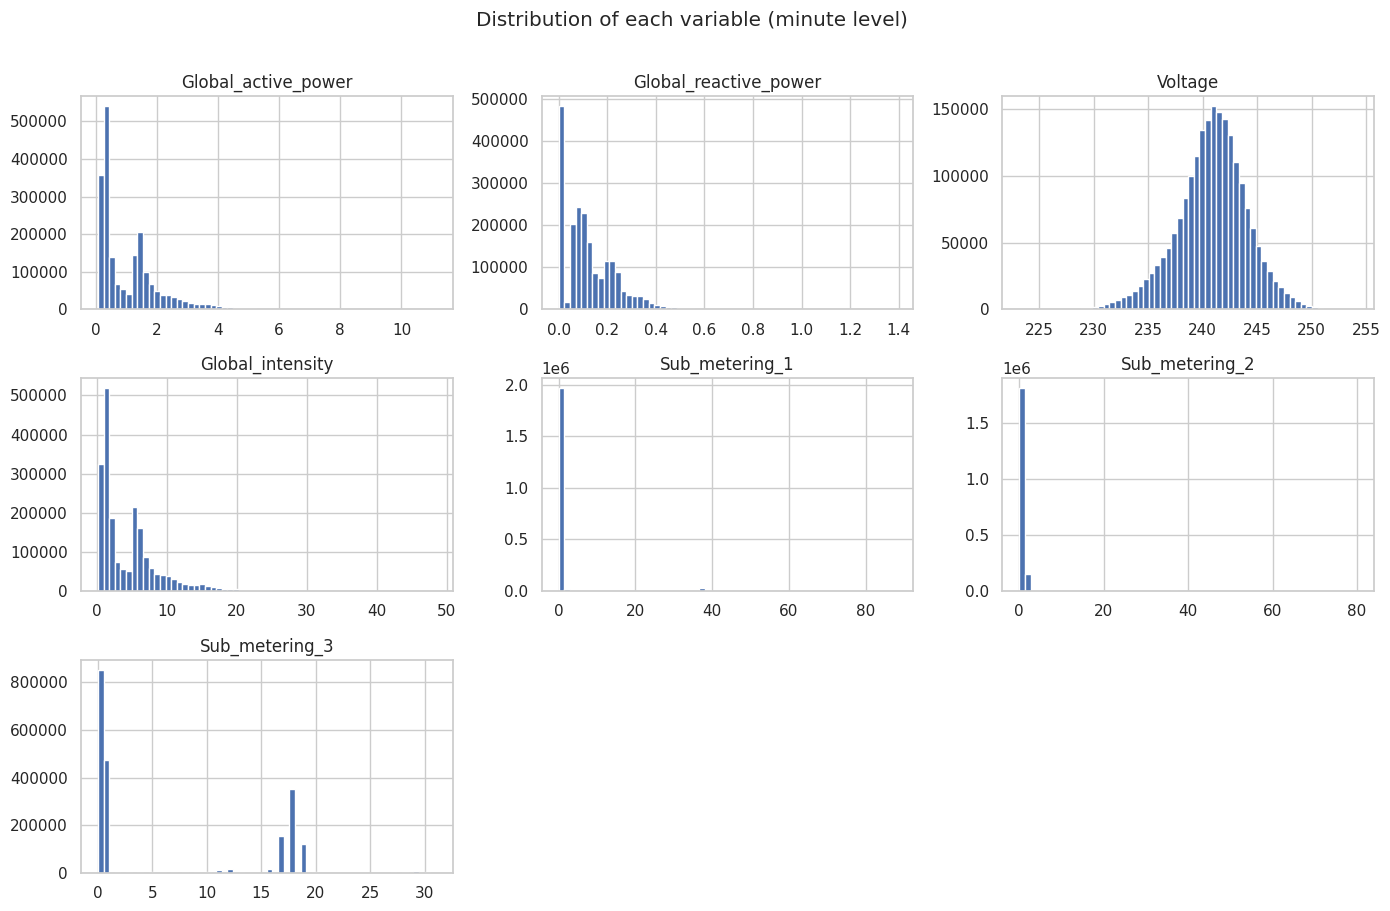

Target values above 3.36 kW: 4.6% of rows
Skewness of the target: 1.79


In [40]:
print(df.describe().T.round(3))

fig, axes = plt.subplots(3, 3, figsize=(14, 9))
for ax, col in zip(axes.ravel(), df.columns):
    df[col].dropna().hist(bins=60, ax=ax)
    ax.set_title(col)
for ax in axes.ravel()[len(df.columns):]:
    ax.axis("off")
plt.suptitle("Distribution of each variable (minute level)", y=1.01)
plt.tight_layout()
plt.show()

# Outliers in the target using the IQR rule
q1, q3 = df[TARGET].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
print(f"Target values above {upper:.2f} kW: {(df[TARGET] > upper).mean() * 100:.1f}% of rows")
print("Skewness of the target:", round(df[TARGET].skew(), 2))

## Preprocessing
Minute-level power, voltage, and intensity readings are averaged by hour, while sub-metering readings are summed. Empty hourly measurements remain missing rather than being interpreted as zero consumption.

In [41]:
# Resample to hourly
hourly_raw = to_hourly(df)

print("Hourly shape:", hourly_raw.shape)
print("Hours with a missing target:", hourly_raw[TARGET].isna().sum())
hourly_raw.head()

Hourly shape: (34589, 7)
Hours with a missing target: 421


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
datetime,,,,,,,
2006-12-16 17:00:00,4.222889,0.229000,234.643889,18.100000,0.0,19.0,607.0
2006-12-16 18:00:00,3.632200,0.080033,234.580167,15.600000,0.0,403.0,1012.0
2006-12-16 19:00:00,3.400233,0.085233,233.232500,14.503333,0.0,86.0,1001.0
2006-12-16 20:00:00,3.268567,0.075100,234.071500,13.916667,0.0,0.0,1007.0
2006-12-16 21:00:00,3.056467,0.076667,237.158667,13.046667,0.0,25.0,1033.0


## Handling missing values
We interpolate only internal gaps of up to six consecutive hours using time-based interpolation. Longer gaps and gaps at the beginning or end of the series remain missing because their values cannot be estimated reliably from nearby observations.

In [42]:
# Fill only short gaps in hourly active power consumption
hourly_clean = hourly_raw.copy()

TARGET = "Global_active_power"
MAX_GAP_HOURS = 6

hourly_clean[TARGET] = hourly_clean[TARGET].interpolate(
    method="time",
    limit=MAX_GAP_HOURS,
    limit_area="inside"
)

print("Missing before:", hourly_raw[TARGET].isna().sum())
print("Missing after:", hourly_clean[TARGET].isna().sum())

# used in Task 2
hourly_clean.to_csv("data/processed/hourly_power.csv")

Missing before: 421
Missing after: 378


## 5. Feature engineering
- **Lags** (`lag_1`, `lag_24`, `lag_168`): consumption 1 hour, 1 day and 1 week earlier
- **Moving averages** (`ma_24`, `ma_168`): the average of the last 24 hours and the last week, including the current hour
- **Calendar** (`hour`, `dayofweek`, `month`)

The target y_next is the next hour's consumption. The current hour's measurements are available when making a one-hour-ahead forecast.

In [43]:
model_data = build_features(hourly_clean)
model_data["y_next"] = model_data[TARGET].shift(-1)

rows_before = len(model_data)
model_data = model_data.dropna()
print(f"Rows before dropping NaN: {rows_before:,}  after: {len(model_data):,}")
model_data.head()

Rows before dropping NaN: 34,589  after: 32,823


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,lag_1,lag_24,lag_168,ma_24,ma_168,hour,dayofweek,month,y_next
datetime,,,,,,,,,,,,,,,,
2006-12-23 17:00:00,5.452533,0.215967,233.644167,23.360000,971.0,40.0,1005.0,4.349100,1.496800,4.222889,3.099713,1.771265,17,5,12,3.879400
2006-12-23 18:00:00,3.879400,0.099767,238.000500,16.363333,0.0,1.0,1041.0,5.452533,2.686967,3.632200,3.149397,1.772736,18,5,12,4.117833
2006-12-23 19:00:00,4.117833,0.205333,238.729333,17.300000,0.0,36.0,1048.0,3.879400,3.938167,3.400233,3.156883,1.777008,19,5,12,4.181400
2006-12-23 20:00:00,4.181400,0.124767,238.518833,17.596667,0.0,21.0,1045.0,4.117833,3.536067,3.268567,3.183772,1.782441,20,5,12,3.288433
2006-12-23 21:00:00,3.288433,0.235767,238.594667,13.893333,0.0,13.0,340.0,4.181400,4.548667,3.056467,3.131262,1.783822,21,5,12,4.327933


## Question 1: How does household electricity consumption change over time?
 from the daily averages graph, we observe that there is no monotonic increase or decrease throughout the data series, but rather there are numerous ups and downs throughout. There seem to be periods of higher use during the winter months, while lower averages occur during some summer months.

## Plot of consumption over time
 The pattern over several years becomes more obvious in the daily averaged series compared to the original minute-based series. However, the presence of short-term peaks and valleys still exists in the series.

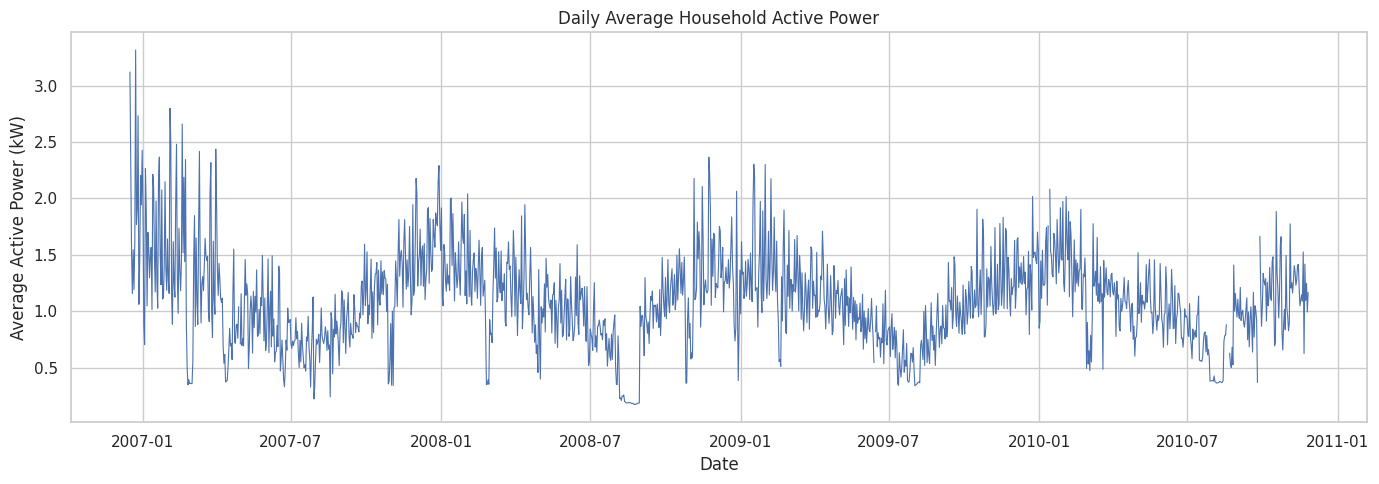

In [44]:
target = "Global_active_power"

# Using hourly_clean which is defined in the previous preprocessing steps
daily = hourly_clean[target].resample("D").mean()

plt.figure(figsize=(14, 5))
plt.plot(daily.index, daily.values, linewidth=0.8)
plt.title("Daily Average Household Active Power")
plt.xlabel("Date")
plt.ylabel("Average Active Power (kW)")
plt.tight_layout()
plt.show()

## Question 2: At what times of day is electricity consumption highest and lowest?
Average consumption is lowest in the early morning, especially around 3 to 5 a.m., at roughly 0.44 kW. It rises sharply around 7 a.m. and reaches its highest level around 8 p.m., at approximately 1.9 kW, before falling later at night. This pattern is consistent with greater household activity in the morning and evening.

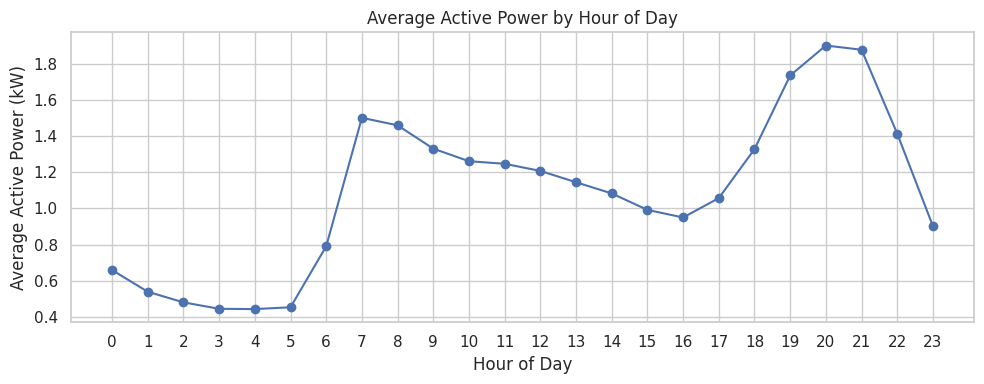

In [45]:
# Question 2 visualisation: average consumption by hour
hourly_profile = hourly_clean[target].groupby(
    hourly_clean.index.hour
).mean()

hourly_profile.plot(figsize=(10, 4), marker="o")
plt.title("Average Active Power by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Average Active Power (kW)")
plt.xticks(range(0, 24))
plt.tight_layout()
plt.show()

## Question 3: Which electrical measurements are most strongly associated with active power consumption?
Global_intensity has the strongest positive correlation with active power (r ≈ 1.00), followed by Sub_metering_3 (0.70), Sub_metering_1 (0.50), and Sub_metering_2 (0.44). Voltage has a moderate negative correlation (−0.38). Correlation shows association, not causation, and the near-perfect intensity relationship reflects how closely these electrical measurements are related.

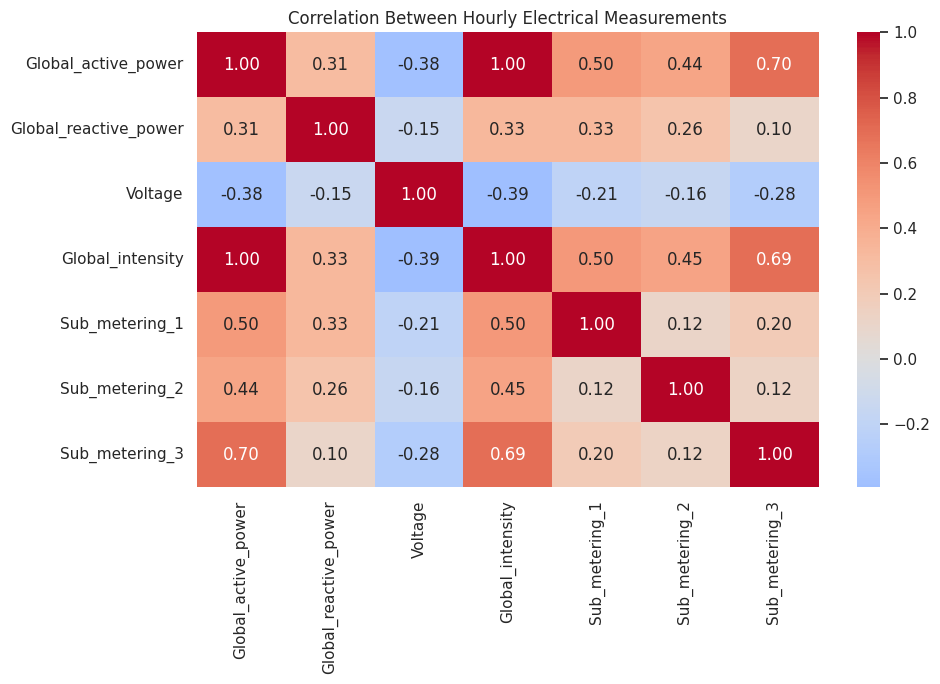

In [46]:
# Question 3: correlation heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(
    hourly_clean.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)
plt.title("Correlation Between Hourly Electrical Measurements")
plt.tight_layout()
plt.show()

## Question 4: Lagged features: Is electricity consumption related to consumption one hour and 24 hours earlier?
Active power has a positive correlation with the previous hour (r ≈ 0.714) and a weaker positive correlation with the same hour on the previous day (r ≈ 0.436). This indicates that recent consumption is more strongly associated with the next observation than consumption from 24 hours earlier. Both lag features may still provide useful forecasting information.

Correlation with previous hour: 0.7136899956697561
Correlation with previous 24 hours: 0.4358331212897404


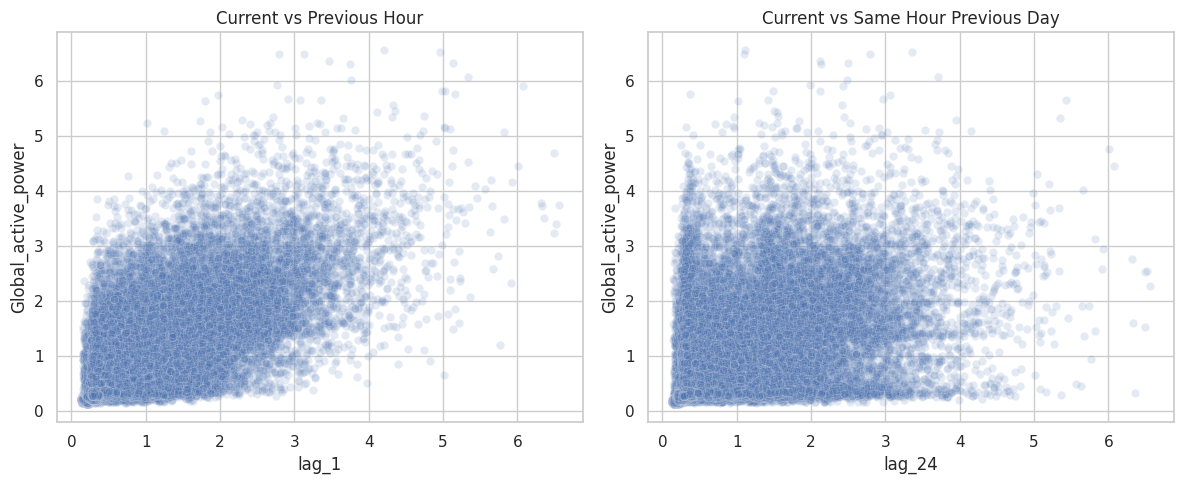

In [47]:
analysis = hourly_clean[[target]].copy()

# Lagged consumption: values from the past
analysis["lag_1"] = analysis[target].shift(1)
analysis["lag_24"] = analysis[target].shift(24)

# Rolling averages using only earlier observations
analysis["ma_24"] = analysis[target].shift(1).rolling(24).mean()
analysis["ma_168"] = analysis[target].shift(1).rolling(168).mean()

# Question 4: lag correlation
print("Correlation with previous hour:",
      analysis[target].corr(analysis["lag_1"]))

print("Correlation with previous 24 hours:",
      analysis[target].corr(analysis["lag_24"]))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.scatterplot(
    data=analysis, x="lag_1", y=target,
    alpha=0.15, ax=axes[0]
)
axes[0].set_title("Current vs Previous Hour")

sns.scatterplot(
    data=analysis, x="lag_24", y=target,
    alpha=0.15, ax=axes[1]
)
axes[1].set_title("Current vs Same Hour Previous Day")

plt.tight_layout()
plt.show()

## Question 5, Moving averages: How do short-term and longer-term consumption patterns differ?
The 24-hour moving average responds more quickly to daily changes, while the 168-hour average is smoother and captures broader weekly patterns. Actual hourly consumption fluctuates sharply around both averages, including occasional spikes. The moving averages help reveal underlying patterns but cannot fully capture sudden changes.

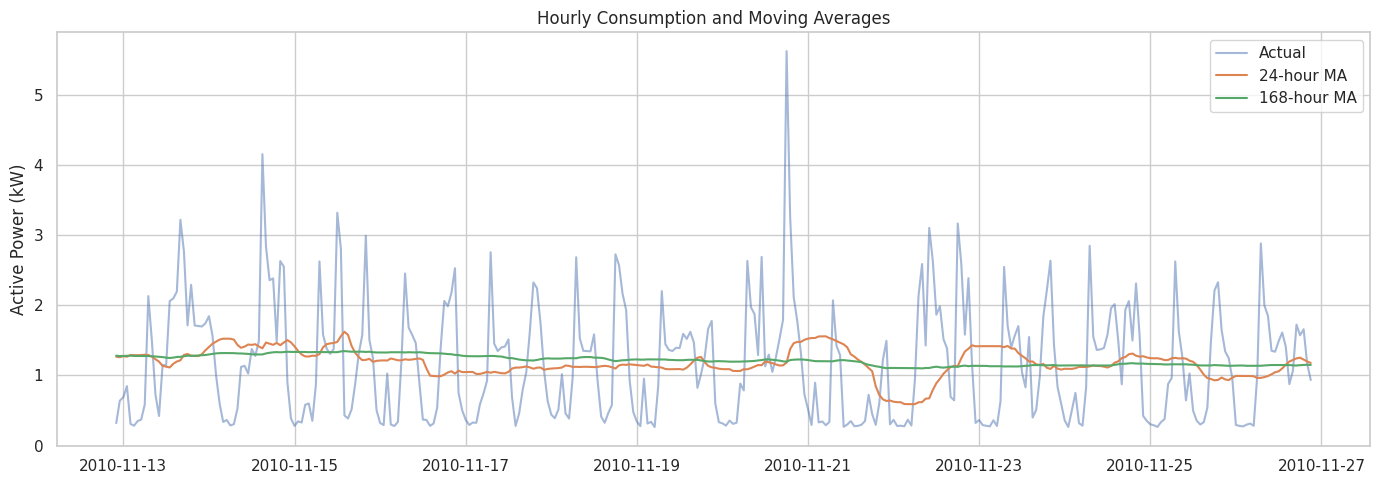

In [48]:
# Question 5: moving averages
sample = analysis.dropna().iloc[-24 * 14:]

plt.figure(figsize=(14, 5))
plt.plot(sample.index, sample[target], label="Actual", alpha=0.5)
plt.plot(sample.index, sample["ma_24"], label="24-hour MA")
plt.plot(sample.index, sample["ma_168"], label="168-hour MA")
plt.title("Hourly Consumption and Moving Averages")
plt.ylabel("Active Power (kW)")
plt.legend()
plt.tight_layout()
plt.show()

## Question 6: Is there a seasonal pattern across the year?
Monthly averages are highest in December and January (about 1.5 kW) and lowest in August (about 0.56 kW). Consumption generally declines from winter into summer and rises again toward the end of the year. This suggests seasonal variation in this household's data, but the pattern should not be generalized to all households.

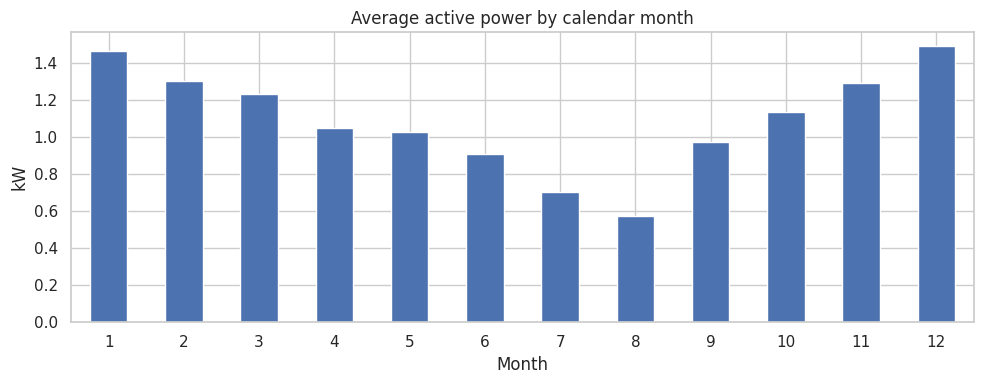

In [49]:
by_month = hourly_clean[TARGET].groupby(hourly_clean.index.month).mean()
by_month.plot(kind="bar", figsize=(10, 4), rot=0)
plt.title("Average active power by calendar month"); plt.xlabel("Month"); plt.ylabel("kW")
plt.tight_layout(); plt.show()

## 3. Model training and experiments
The target is the next hour's active power. A persistence baseline predicts that the next hour equals the current hour; Random Forest and Gradient Boosting models are compared using the same chronological train/test period. Model performance is assessed with MAE, RMSE, and R².

In [50]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

split = int(len(model_data) * 0.8)
train, test = model_data.iloc[:split], model_data.iloc[split:]
y_train, y_test = train["y_next"], test["y_next"]

print("Data window:", model_data.index.min(), "to", model_data.index.max(),
      f"({len(model_data):,} usable hourly rows)")
print("Train:", train.index.min(), "to", train.index.max(), f"({len(train):,} rows)")
print("Test: ", test.index.min(), "to", test.index.max(), f"({len(test):,} rows)")

# One list for every experiment, one helper to log them
results, fitted = [], {}

def log_experiment(name, model_name, feature_set, params, y_true, y_pred):
    results.append({
        "Experiment": name,
        "Model": model_name,
        "Features": feature_set,
        "Hyperparameters": str(params),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R2": r2_score(y_true, y_pred),
    })

def run_experiment(name, model, feature_set, params):
    cols = FEATURE_SETS[feature_set]
    model.fit(train[cols], y_train)
    pred = model.predict(test[cols])
    log_experiment(name, type(model).__name__, feature_set, params, y_test, pred)
    fitted[name] = {"model": model, "set": feature_set, "pred": pred}

# Baseline: next hour = current hour
log_experiment("Baseline", "Persistence", "current value only", {}, y_test, test[TARGET])

Data window: 2006-12-23 17:00:00 to 2010-11-26 20:00:00 (32,823 usable hourly rows)
Train: 2006-12-23 17:00:00 to 2010-01-26 08:00:00 (26,258 rows)
Test:  2010-01-26 09:00:00 to 2010-11-26 20:00:00 (6,565 rows)


In [51]:
FSET_A = "A: current + lags + calendar"
FSET_B = "B: A + moving averages"
FSET_C = "C: B + electrical measurements"

def rf(params):
    return RandomForestRegressor(**params, random_state=SEED, n_jobs=-1)

# Exp 1 to 3: same model, feature groups added one at a time
RF_BASE = {"n_estimators": 100, "max_depth": 12, "min_samples_leaf": 2}
run_experiment("Exp 1", rf(RF_BASE), FSET_A, RF_BASE)
run_experiment("Exp 2", rf(RF_BASE), FSET_B, RF_BASE)
run_experiment("Exp 3", rf(RF_BASE), FSET_C, RF_BASE)

# Exp 4: more trees, deeper
P4 = {"n_estimators": 200, "max_depth": 20, "min_samples_leaf": 2}
run_experiment("Exp 4", rf(P4), FSET_C, P4)

# Exp 5: stronger regularisation (shallower trees, larger leaves)
P5 = {"n_estimators": 100, "max_depth": 8, "min_samples_leaf": 5}
run_experiment("Exp 5", rf(P5), FSET_C, P5)

# Exp 6: a different model family
P6 = {"n_estimators": 300, "learning_rate": 0.1, "max_depth": 3}
run_experiment("Exp 6", GradientBoostingRegressor(**P6, random_state=SEED), FSET_C, P6)

In [52]:
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [10, 15],
    "min_samples_leaf": [2, 5],
}

grid = GridSearchCV(
    RandomForestRegressor(random_state=SEED, n_jobs=-1),
    param_grid,
    cv=TimeSeriesSplit(n_splits=3),
    scoring="neg_root_mean_squared_error",
)
grid.fit(train[FEATURE_SETS[FSET_C]], y_train)
print("Best parameters:", grid.best_params_)

# Show every combination that was tried
tuning = pd.DataFrame(grid.cv_results_)[["params", "mean_test_score", "rank_test_score"]]
tuning["cv_rmse"] = -tuning["mean_test_score"]
display(tuning.sort_values("rank_test_score")[["params", "cv_rmse", "rank_test_score"]])

run_experiment("Exp 7", rf(grid.best_params_), FSET_C, grid.best_params_)

Best parameters: {'max_depth': 15, 'min_samples_leaf': 5, 'n_estimators': 200}


,params,cv_rmse,rank_test_score
7,"{'max_depth': 15, 'min_samples_leaf': 5, 'n_es...",0.543004,1
6,"{'max_depth': 15, 'min_samples_leaf': 5, 'n_es...",0.544375,2
3,"{'max_depth': 10, 'min_samples_leaf': 5, 'n_es...",0.544967,3
2,"{'max_depth': 10, 'min_samples_leaf': 5, 'n_es...",0.546120,4
1,"{'max_depth': 10, 'min_samples_leaf': 2, 'n_es...",0.550527,5
5,"{'max_depth': 15, 'min_samples_leaf': 2, 'n_es...",0.550743,6
0,"{'max_depth': 10, 'min_samples_leaf': 2, 'n_es...",0.550919,7
4,"{'max_depth': 15, 'min_samples_leaf': 2, 'n_es...",0.551898,8


In [53]:
results_df = pd.DataFrame(results)

base_rmse = results_df.loc[results_df["Experiment"] == "Baseline", "RMSE"].iloc[0]
results_df["vs baseline (%)"] = (base_rmse - results_df["RMSE"]) / base_rmse * 100

final_table = (results_df[["Experiment", "Model", "Features", "Hyperparameters",
                           "MAE", "RMSE", "R2", "vs baseline (%)"]]
               .sort_values("RMSE").reset_index(drop=True))
final_table.index += 1
final_table.index.name = "Rank"
final_table = final_table.round(4)

final_table.to_csv("outputs/all_experiments.csv")
final_table

,Experiment,Model,Features,Hyperparameters,MAE,RMSE,R2,vs baseline (%)
Rank,,,,,,,,
1,Exp 7,RandomForestRegressor,C: B + electrical measurements,"{'max_depth': 15, 'min_samples_leaf': 5, 'n_es...",0.3215,0.4684,0.6190,23.0287
2,Exp 3,RandomForestRegressor,C: B + electrical measurements,"{'n_estimators': 100, 'max_depth': 12, 'min_sa...",0.3216,0.4695,0.6172,22.8501
3,Exp 4,RandomForestRegressor,C: B + electrical measurements,"{'n_estimators': 200, 'max_depth': 20, 'min_sa...",0.3229,0.4701,0.6163,22.7579
4,Exp 6,GradientBoostingRegressor,C: B + electrical measurements,"{'n_estimators': 300, 'learning_rate': 0.1, 'm...",0.3311,0.4706,0.6155,22.6744
5,Exp 5,RandomForestRegressor,C: B + electrical measurements,"{'n_estimators': 100, 'max_depth': 8, 'min_sam...",0.3341,0.4800,0.5999,21.1261
6,Exp 2,RandomForestRegressor,B: A + moving averages,"{'n_estimators': 100, 'max_depth': 12, 'min_sa...",0.3329,0.4863,0.5894,20.0911
7,Exp 1,RandomForestRegressor,A: current + lags + calendar,"{'n_estimators': 100, 'max_depth': 12, 'min_sa...",0.3393,0.4901,0.5829,19.4630
8,Baseline,Persistence,current value only,{},0.3996,0.6085,0.3569,0.0000


## Compare & explain
The persistence baseline has an RMSE of 0.6085 kW. The best result in this run is Experiment 7, a tuned Random Forest using current measurements, lag features, moving averages, calendar features, and electrical measurements; its test RMSE is 0.4684 kW, about 23.0% lower than the baseline. Its MAE is 0.3215 kW and R² is 0.6190. These results indicate improvement over the baseline, though prediction errors remain and performance should be tested on future periods.

Best experiment: Exp 7 | C: B + electrical measurements


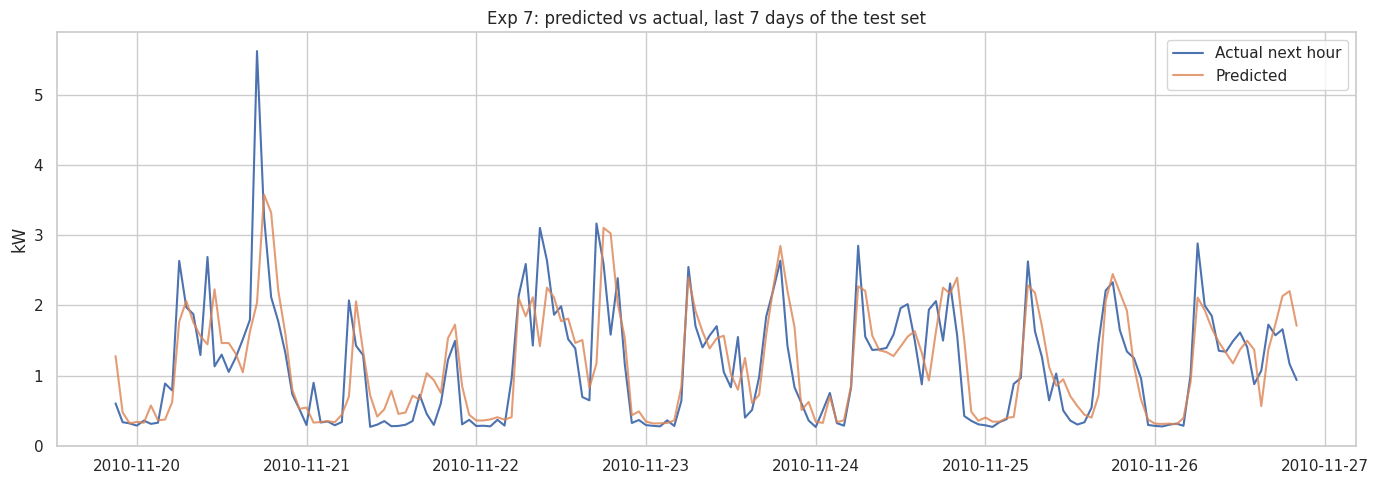

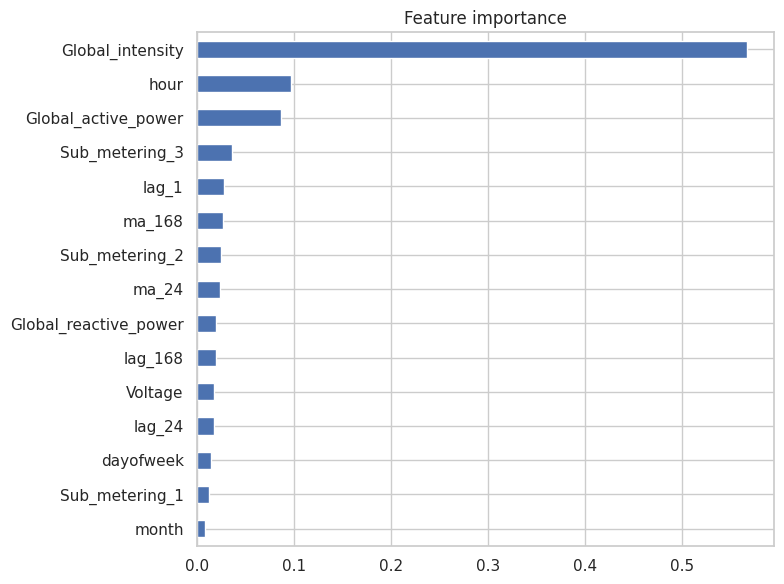

In [54]:
# Pick the best model by test RMSE (excluding the baseline)
candidates = results_df[results_df["Experiment"] != "Baseline"]
best_name = candidates.loc[candidates["RMSE"].idxmin(), "Experiment"]
best = fitted[best_name]
print("Best experiment:", best_name, "|", best["set"])

# Predicted vs actual, last 7 days of the test set
last = test.iloc[-168:]
plt.figure(figsize=(14, 5))
plt.plot(last.index, last["y_next"], label="Actual next hour")
plt.plot(last.index, best["pred"][-168:], label="Predicted", alpha=0.8)
plt.title(f"{best_name}: predicted vs actual, last 7 days of the test set")
plt.ylabel("kW"); plt.legend(); plt.tight_layout(); plt.show()

# What the model relies on
model = best["model"]
cols = FEATURE_SETS[best["set"]]
if hasattr(model, "feature_importances_"):
    imp = pd.Series(model.feature_importances_, index=cols).sort_values()
    imp.plot(kind="barh", figsize=(8, 6), title="Feature importance")
    plt.tight_layout(); plt.show()

Mean consumption  train: 1.105  test: 1.032


,actual,pred,abs_err
datetime,,,
2010-11-20 17:00:00,5.626833,2.039167,3.587666
2010-02-21 10:00:00,5.090800,1.672968,3.417832
2010-11-14 14:00:00,4.156567,1.300586,2.855981
2010-02-21 13:00:00,4.638200,1.889236,2.748964
2010-11-04 07:00:00,4.418900,1.829969,2.588931
2010-02-13 11:00:00,3.924133,1.381534,2.542600
2010-01-27 16:00:00,4.079833,1.546875,2.532958
2010-09-17 20:00:00,0.573833,3.034883,2.461050
2010-06-23 20:00:00,3.941100,1.520101,2.420999


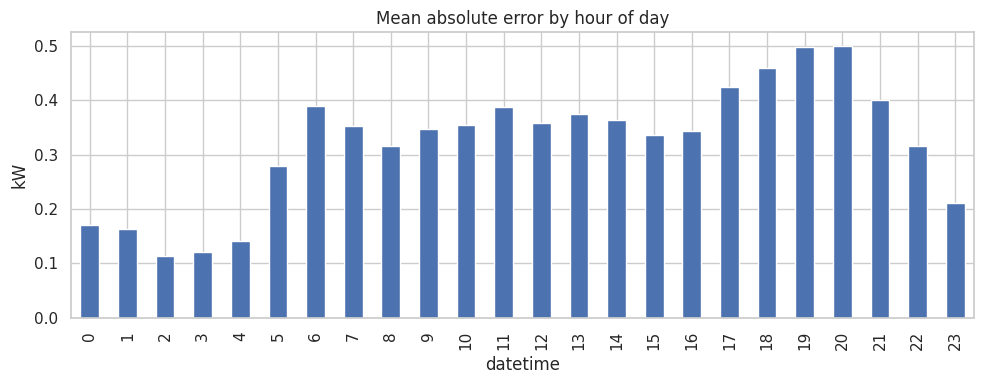

In [56]:
err = pd.DataFrame({"actual": test["y_next"], "pred": best["pred"]}, index=test.index)
err["abs_err"] = (err["actual"] - err["pred"]).abs()

print("Mean consumption  train:", round(train["y_next"].mean(), 3),
      " test:", round(test["y_next"].mean(), 3))

display(err.sort_values("abs_err", ascending=False).head(10))

err.groupby(err.index.hour)["abs_err"].mean().plot(
    kind="bar", figsize=(10, 4), title="Mean absolute error by hour of day")
plt.ylabel("kW"); plt.tight_layout(); plt.show()

## Saving the best model
The selected model and its feature-column list are saved together in models/best_model.pkl. Task 4 should load this bundle and use the same feature names, order, and preprocessing logic when generating a forecast.

In [55]:
bundle = {
    "model": best["model"],
    "feature_cols": FEATURE_SETS[best["set"]],
    "target": TARGET,
    "horizon": "next hour",
    "experiment": best_name,
}
joblib.dump(bundle, "models/best_model.pkl", compress=3)
print("Model size (MB):", round(os.path.getsize("models/best_model.pkl") / 1e6, 1))
print("If this is over about 50 MB, lower n_estimators or max_depth, or share it via Drive.")

Model size (MB): 18.6
If this is over about 50 MB, lower n_estimators or max_depth, or share it via Drive.


## Limitations
- The data comes from a single household, so the model may not generalise to other homes.
- Short gaps (up to 6 hours) were interpolated, so those values are estimates, not measurements. Longer gaps were excluded (378 hours remain missing).
- The data covers about four years, so seasonal patterns rest on only a few yearly cycles.
- The best model was chosen using the test set, so its score is slightly optimistic. The top models differ by about 0.002 RMSE, which is within noise.
- The largest errors are under-predicted sudden spikes in use, which the lag and moving-average features cannot anticipate.